# Starter code: clustering across dataset shapes

This notebook generates six synthetic datasets with different cluster geometries and plots their ground-truth labels.
Use it to generate and visualize the data, then add your own code to fit and compare the clustering models.

The datasets follow scikit-learn's toy-dataset clustering comparison.
Each dataset has 500 points in two dimensions, standardized to zero mean and unit variance per feature.
Do not change the random seeds, so that everyone works with the same data.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import StandardScaler

## Generate the datasets

`make_datasets()` returns a list of dictionaries, one per dataset, with keys

- `name`: the dataset's title,
- `X`: a standardized `(500, 2)` array of points,
- `y`: the ground-truth cluster labels, or `None` for the dataset with no cluster structure,
- `n_clusters`: the number of ground-truth clusters, or `None` for the dataset with no cluster structure.

In [8]:
N_SAMPLES = 500
SEED = 170


def make_datasets(n_samples=N_SAMPLES, seed=SEED):
    noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05, random_state=seed)
    noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05, random_state=seed)
    varied = datasets.make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=seed)

    X_blobs, y_blobs = datasets.make_blobs(n_samples=n_samples, random_state=seed)
    stretch = np.array([[0.6, -0.6], [-0.4, 0.8]])
    aniso = (X_blobs @ stretch, y_blobs)

    blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
    no_structure = (np.random.default_rng(seed).random((n_samples, 2)), None)

    raw = [
        ("Noisy Circles", noisy_circles),
        ("Noisy Moons", noisy_moons),
        ("Varied Blobs", varied),
        ("Anisotropic Blobs", aniso),
        ("Blobs", blobs),
        ("No Structure", no_structure),
    ]
    out = []
    for name, (X, y) in raw:
        out.append({
            "name": name,
            "X": StandardScaler().fit_transform(X),
            "y": y,
            "n_clusters": None if y is None else len(np.unique(y)),
        })
    return out


data = make_datasets()
for d in data:
    print(f"{d['name']:18s} X shape {d['X'].shape}  ground-truth clusters: {d['n_clusters']}")

Noisy Circles      X shape (500, 2)  ground-truth clusters: 2
Noisy Moons        X shape (500, 2)  ground-truth clusters: 2
Varied Blobs       X shape (500, 2)  ground-truth clusters: 3
Anisotropic Blobs  X shape (500, 2)  ground-truth clusters: 3
Blobs              X shape (500, 2)  ground-truth clusters: 3
No Structure       X shape (500, 2)  ground-truth clusters: None


## Plotting helper

`plot_grid(data, rows)` draws one column per dataset and one row per entry of `rows`.
Each entry of `rows` is a pair `(row_title, labels)`, where `labels` is a list with one label array per dataset (in the same order as `data`), or `None` to plot a dataset's points in gray.
Points labeled `-1`, which is how DBSCAN marks noise, are drawn as black crosses.

In [9]:
def plot_grid(data, rows, panel_size=2.5):
    n_rows, n_cols = len(rows), len(data)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(panel_size * n_cols, panel_size * n_rows),
                             squeeze=False)
    for i, (row_title, labels) in enumerate(rows):
        for j, d in enumerate(data):
            ax = axes[i, j]
            X = d["X"]
            lab = None if labels is None else labels[j]
            if lab is None:
                ax.scatter(X[:, 0], X[:, 1], s=6, color="gray")
            else:
                lab = np.asarray(lab)
                noise = lab == -1
                ax.scatter(X[~noise, 0], X[~noise, 1], s=6, c=lab[~noise], cmap="viridis")
                ax.scatter(X[noise, 0], X[noise, 1], s=10, color="black", marker="x")
            ax.set_xticks([])
            ax.set_yticks([])
            if i == 0:
                ax.set_title(d["name"], fontsize=10)
            if j == 0:
                ax.set_ylabel(row_title, fontsize=10)
    fig.tight_layout()
    return fig

## Ground truth

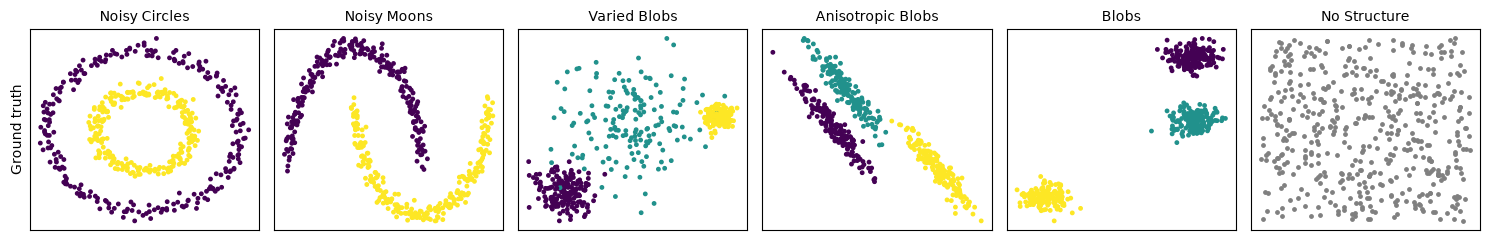

In [10]:
ground_truth = [d["y"] for d in data]
plot_grid(data, [("Ground truth", ground_truth)])
plt.show()

## Your models

Fit DBSCAN, KMeans, hierarchical (agglomerative) clustering, and spectral clustering to each dataset.
Collect each model's predicted labels in a list with one array per dataset, in the same order as `data`, and add a row to `rows`.
For example, with your own model in place of `...`:

```python
dbscan_labels = [... .fit_predict(d["X"]) for d in data]
rows.append(("DBSCAN", dbscan_labels))
```

The final figure should have the ground-truth row followed by one row for each of the four models.

/Users/khanhpham/Desktop/CS5805/Homework7/.venv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/khanhpham/Desktop/CS5805/Homework7/.venv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/khanhpham/Desktop/CS5805/Homework7/.venv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


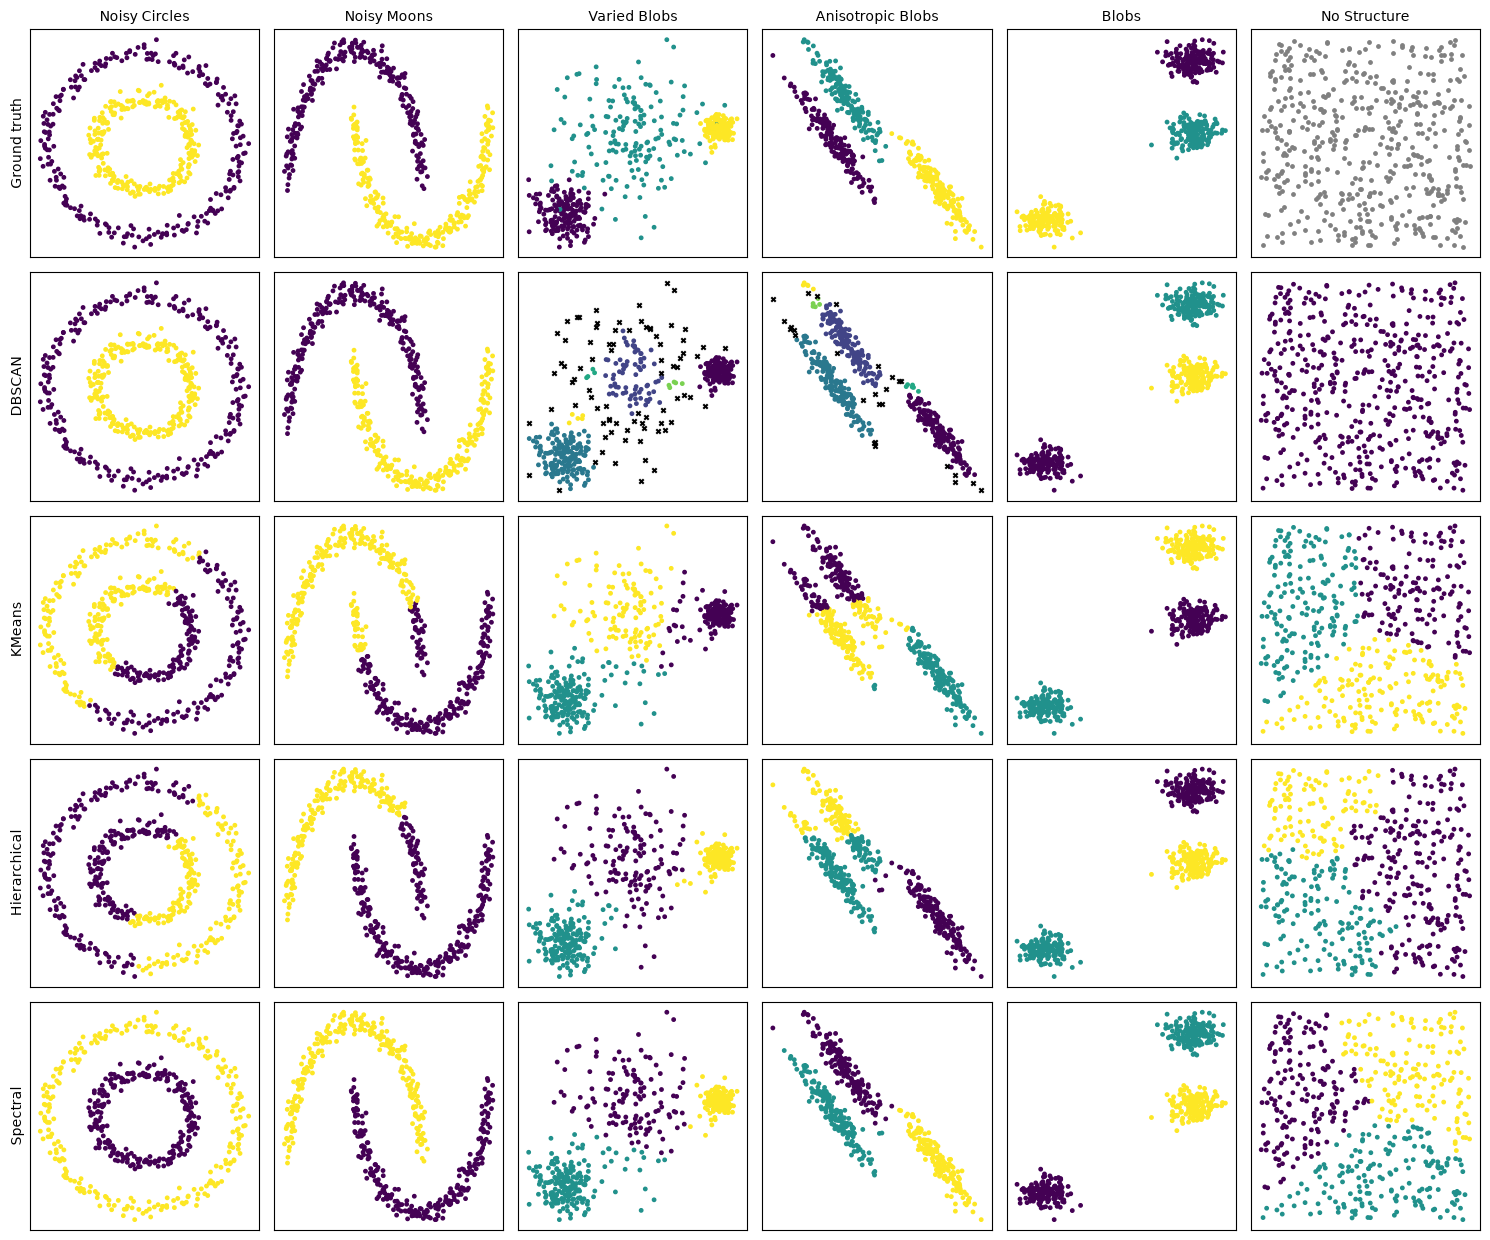

In [11]:
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering, SpectralClustering

rows = [("Ground truth", ground_truth)]

# DBSCAN eps chosen per dataset (data is standardized)
eps_list = [0.3, 0.3, 0.18, 0.15, 0.3, 0.3]

# DBSCAN
dbscan_labels = [DBSCAN(eps=eps, min_samples=5).fit_predict(d["X"])
                 for d, eps in zip(data, eps_list)]
rows.append(("DBSCAN", dbscan_labels))

# Number of clusters (No Structure has no ground truth -> use 3)
k_list = [d["n_clusters"] if d["n_clusters"] else 3 for d in data]

# KMeans
kmeans_labels = [KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(d["X"])
                 for d, k in zip(data, k_list)]
rows.append(("KMeans", kmeans_labels))

# Hierarchical (Agglomerative)
hier_labels = [AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(d["X"])
               for d, k in zip(data, k_list)]
rows.append(("Hierarchical", hier_labels))

# Spectral
spectral_labels = [SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                      n_neighbors=10, random_state=42).fit_predict(d["X"])
                   for d, k in zip(data, k_list)]
rows.append(("Spectral", spectral_labels))

plot_grid(data, rows)
plt.show()

## Question 7(a): 
**Anticipated challenges for DBSCAN:**
- **Noisy Circles / Noisy Moons:** Not convex, but density is uniform.
- **Blobs:** Easy, well separated, same density.
- **No Structure:** Uniform noise, DBSCAN will put everything in one cluster (or all noise), which is actually reasonable.

In [12]:
from sklearn.metrics import adjusted_rand_score

print(f"{'Dataset':18s} {'DBSCAN':>8s} {'KMeans':>8s} {'Hier':>8s} {'Spectral':>8s}")
for j, d in enumerate(data):
    if d["y"] is None:
        continue
    scores = [adjusted_rand_score(d["y"], r[1][j]) for r in rows[1:]]
    print(f"{d['name']:18s} " + " ".join(f"{s:8.3f}" for s in scores))

Dataset              DBSCAN   KMeans     Hier Spectral
Noisy Circles         1.000   -0.002   -0.002    1.000
Noisy Moons           1.000    0.483    0.565    1.000
Varied Blobs          0.796    0.731    0.853    0.803
Anisotropic Blobs     0.870    0.572    0.620    0.976
Blobs                 1.000    1.000    1.000    1.000


## Question 7(d): Observations
No single model was best everywhere. On **Noisy Circles and Noisy Moons**, DBSCAN and Spectral got a perfect ARI of 1.0, while KMeans and Ward hierarchical cut the rings/moons in half. On **Varied Blobs**, hierarchical did best and DBSCAN marked a lot of the sparse blob as noise, which is the varying-density problem I expected in (a). On simple **Blobs** every model got 1.0, and on **No Structure** DBSCAN correctly gave one cluster while the others forced 3 fake clusters. Overall, Spectral was the most reliable, and DBSCAN is great for shapes as long as density is similar.